In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV, PredefinedSplit, ParameterGrid
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, accuracy_score

BASE_DIR = "/content/drive/MyDrive/NLP project"

train = pd.read_csv(f"{BASE_DIR}/train.csv")
val = pd.read_csv(f"{BASE_DIR}/val.csv")
test = pd.read_csv(f"{BASE_DIR}/test.csv")

In [ ]:
best_params = {"svm__C": 0.3, "tfidf__min_df": 1, "tfidf__ngram_range": (1, 2),
               "tfidf__stop_words": None, "tfidf__sublinear_tf": True}
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")),
    ("svm", LinearSVC(class_weight="balanced", max_iter=5000)),
])

Train: 12.7s | Inference: 1.29s
                      precision    recall  f1-score   support

             Anxiety      0.762     0.843     0.800       542
             Bipolar      0.799     0.787     0.793       375
          Depression      0.763     0.673     0.715      2261
              Normal      0.911     0.941     0.926      2403
Personality disorder      0.728     0.560     0.633       134
              Stress      0.574     0.642     0.606       344
            Suicidal      0.683     0.736     0.708      1595

            accuracy                          0.785      7654
           macro avg      0.746     0.740     0.740      7654
        weighted avg      0.785     0.785     0.783      7654



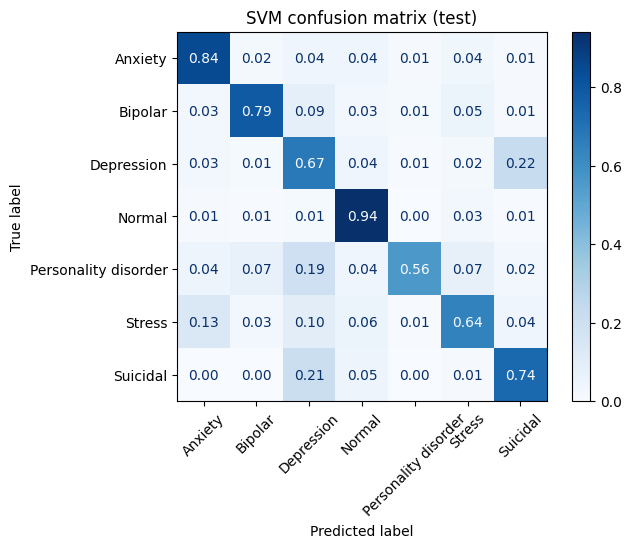

In [ ]:
start = time.time()
svm = pipe.set_params(**best_params).fit(train["statement"], train["status"])
train_time = time.time() - start

start = time.time()
y_pred = svm.predict(test["statement"])
inference_time = time.time() - start

print(f"Train: {train_time:.1f}s | Inference: {inference_time:.2f}s")
print(classification_report(test["status"], y_pred, digits=3))

ConfusionMatrixDisplay.from_predictions(test["status"], y_pred, normalize="true",
                                        xticks_rotation=45, values_format=".2f", cmap="Blues")
plt.title("SVM confusion matrix (test)")
plt.show()

In [ ]:
pd.DataFrame({"id": test["id"], "true": test["status"], "pred": y_pred}).to_csv(f"{BASE_DIR}/svm_preds.csv", index=False)

pd.DataFrame([{
    "model": "svm",
    "accuracy": accuracy_score(test["status"], y_pred),
    "macro_f1": f1_score(test["status"], y_pred, average="macro"),
    "weighted_f1": f1_score(test["status"], y_pred, average="weighted"),
    "train_time_s": train_time,
    "inference_time_s": inference_time,
}]).to_csv(f"{BASE_DIR}/svm_metrics.csv", index=False)

In [ ]:
scores = svm.decision_function(test["statement"])
pd.DataFrame(scores, columns=svm.classes_).assign(id=test["id"].values).to_csv(f"{BASE_DIR}/svm_scores.csv", index=False)

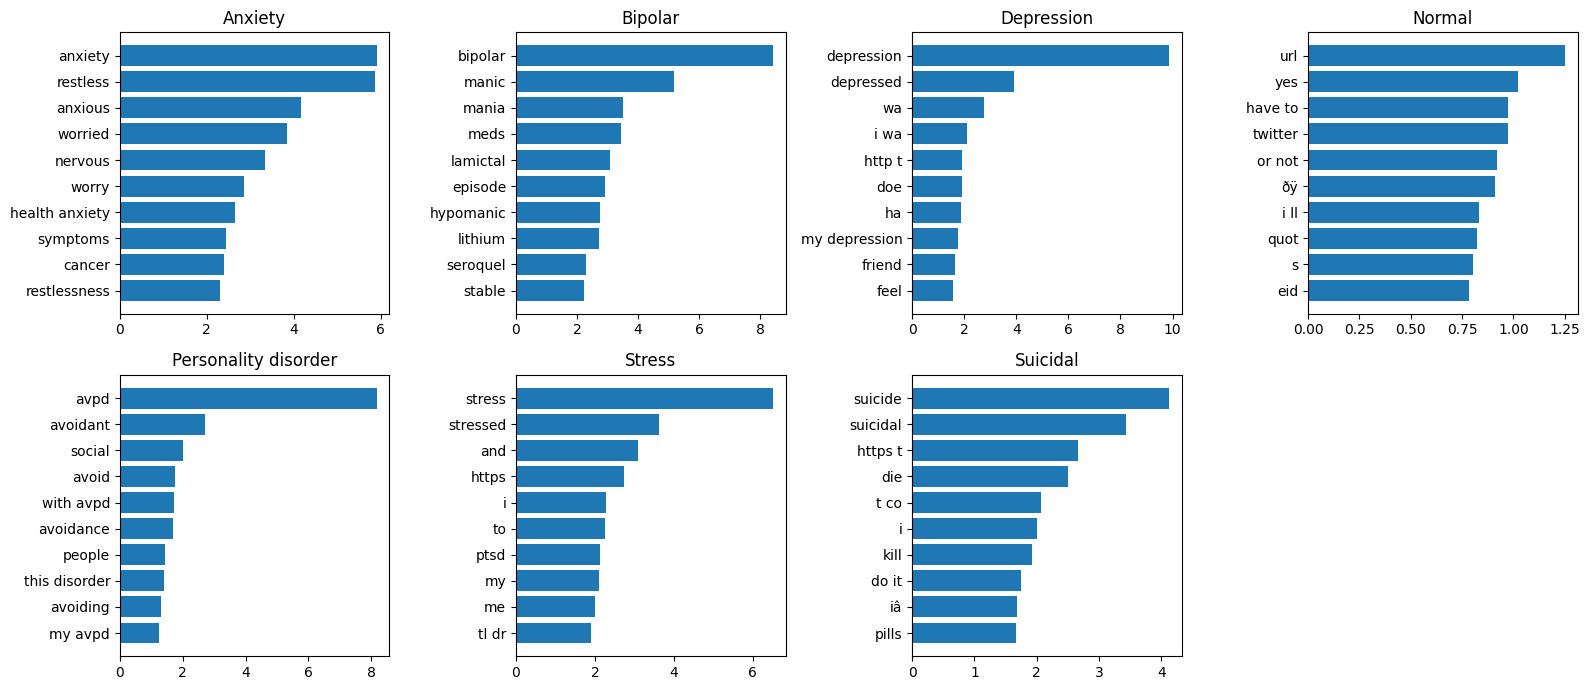

In [ ]:
vocab = svm.named_steps["tfidf"].get_feature_names_out()
coefs = svm.named_steps["svm"].coef_

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, cls, w in zip(axes.ravel(), svm.classes_, coefs):
    top = np.argsort(w)[-10:]
    ax.barh(vocab[top], w[top])
    ax.set_title(cls)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
import joblib
joblib.dump(svm, f"{BASE_DIR}/svm_model.joblib")

['/content/drive/MyDrive/NLP project/svm_model.joblib']